In [19]:
import numpy as np
from scipy.interpolate import interp1d
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker

def negativos_inclusos(i_sec_ensaio):
    i_sec_ensaio_invertida = i_sec_ensaio[::-1]
    i_sec_ensaio_invertida = [-1 * elemento for elemento in i_sec_ensaio_invertida]
    i_sec_ensaio = i_sec_ensaio_invertida + i_sec_ensaio
    return i_sec_ensaio


omega = 2*np.pi*60
# Dados fornecidos
i_sec_ensaio = [3.000e-03,
                9.000e-03,
                2.300e-02,
                6.300e-02,
                1.160e-01,
                1.540e-01,
                2.260e-01,
                3.470e-01,
                6.540e-01,
                1.071e+00,
                1.310e+00,
                1.915e+00,
                3.731e+00,
                6.055e+00]

e_sec_ensaio = [1.,
                4.,
                12.,
                52.,
                83.,
                93.,
                106.,
                121.,
                135.,
                141.,
                143.,
                145.,
                147.,
                148.]

i_sec_ensaio = negativos_inclusos(i_sec_ensaio)
e_sec_ensaio = negativos_inclusos(e_sec_ensaio)

In [20]:
def indutancia(i_value, omega, N):
    X = np.gradient(e_interpolated(i_value), i_value)
    L = X / omega
    R = N**2 / L # relutância
    return L

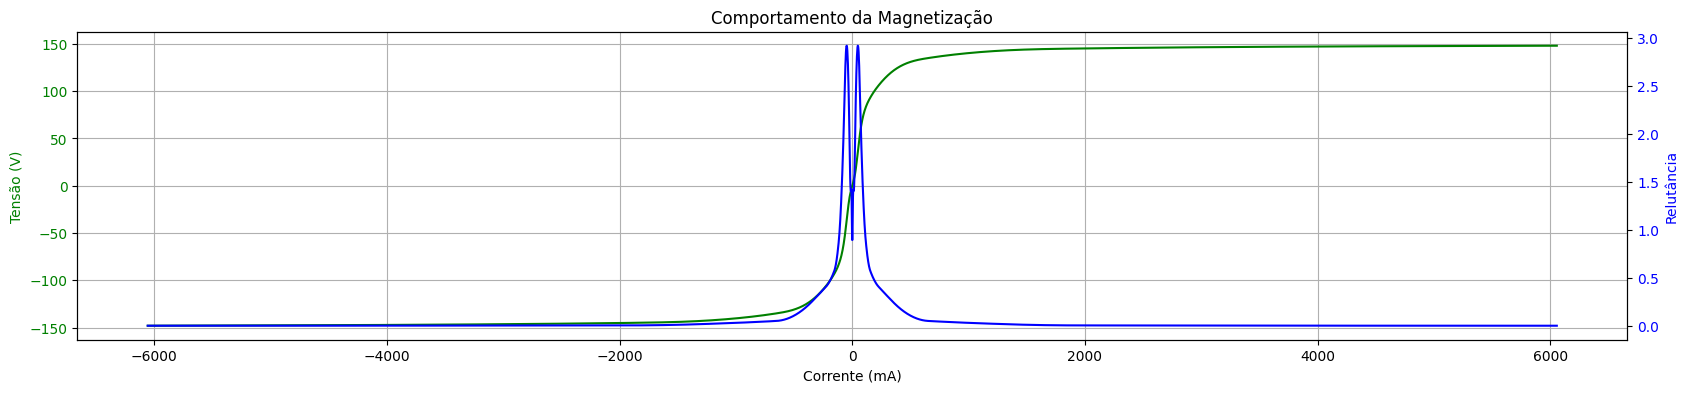

In [21]:
# Criando uma função de interpolação para e_sec_ensaio
e_interpolated = interp1d(i_sec_ensaio, e_sec_ensaio, kind='cubic', fill_value="extrapolate")
i_interpolated = interp1d(e_sec_ensaio, i_sec_ensaio, kind='cubic', fill_value="extrapolate")

# Visualização
i_values = np.linspace(min(i_sec_ensaio), max(i_sec_ensaio), 5000)
e_values = np.linspace(min(e_sec_ensaio), max(e_sec_ensaio), 5000)

N = 100 / 5
indutancia_values = indutancia(i_values, omega, N)


# Criando o gráfico
fig1, axs1 = plt.subplots(figsize=(20, 4))

# Configurando o primeiro eixo (axs1)
axs1.plot(1e3*i_values, e_interpolated(i_values), 'g-', label='Interpolação')  # Linha verde
axs1.set_xlabel('Corrente (mA)')
axs1.set_ylabel('Tensão (V)', color='g')  # Cor do rótulo do eixo Y
axs1.tick_params(axis='y', labelcolor='g')  # Cor dos ticks do eixo Y
axs1.set_title('Comportamento da Magnetização')
# axs1.yaxis.set_major_locator(ticker.LinearLocator(10))
axs1.grid(which='both')

# Configurando o segundo eixo (axs2)
axs2 = axs1.twinx()
axs2.plot(1e3*i_values, indutancia_values, 'b-', label='Relutância')  # Linha azul
axs2.set_ylabel(r'Relutância', color='b')  # Cor do rótulo do eixo Y
axs2.tick_params(axis='y', labelcolor='b')  # Cor dos ticks do eixo
# axs2.yaxis.set_major_locator(ticker.LinearLocator(10))

# Mostrando o gráfico
plt.show()

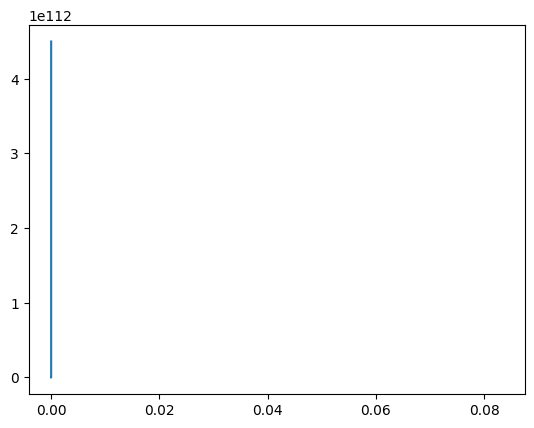

In [26]:
RB = 1

dt = 1e-6
tempo = np.arange(0, 5/60, dt)
i1 = 100 * np.sin(omega*tempo)
Di1 = np.gradient(i1, tempo)
i2 = np.zeros(len(tempo))
im = np.zeros(len(tempo))
v2 = np.zeros(len(tempo))
L = np.zeros(len(tempo))
v2[0] = 2

for k in range(len(tempo)-1):
    im[k] = i1[k]/N - v2[k]/RB
    # if im[k] > 6.055e+00:
    #     im[k] = 6.055e+00
    # elif im[k] < -6.055e+00:
    #     im[k] = -6.055e+00

    v2[k] = e_interpolated(im[k])
    X = v2[k] / im[k]
    L[k] = X / omega

    v2[k+1] = v2[k] + dt*RB*(Di1[k]/N - v2[k]/L[k])

plt.plot(tempo, im)

In [23]:
im

array([ 3.   , -6.055,  6.055, ..., -6.055,  6.055,  0.   ])

In [27]:
v2

array([-1.45135207e+02,  8.07961631e+04, -1.56845952e+13, ...,
                   nan,             nan,             nan])